# 2. Single-Client Fine-Tuning and Server-Side Privacy Attack

## Goal

Notebook 1 produced the common starting model for the federated learning experiments: a **MobileNetV4 Conv Small 0.5** model fine-tuned on 10 QuickDraw classes using public data.

This notebook moves from centralized preparation to the client side of FL. We simulate one client receiving that global checkpoint, adapting it on a very small private dataset, and uploading a model update back to the server. We then examine what an honest-but-curious server can infer from that update.

The objective is to isolate three engineering questions:

1. How should a lightweight pretrained vision model be adapted when a client has only a few local samples?
2. What does the client actually need to send back to the server?
3. How much private information can be exposed by that update, even when the raw images never leave the client?

## Starting model

We continue with the **small model** from Notebook 1:

`mobilenetv4_conv_small_050.e3000_r224_in1k`

The original ImageNet classifier was replaced in Notebook 1 by a 10-class QuickDraw head. For this task-specific version, the notebook reports about **970.8K total parameters**, of which only **12.8K parameters** belong to the 10-class classifier head.

That distinction matters for FL. The client does not need to retrain the complete visual backbone for a five-image local dataset. Updating only the head reduces local computation, limits overfitting, and produces a much smaller parameter update. The backbone remains the shared visual representation learned from ImageNet and the public QuickDraw fine-tuning stage.

## Local client setup

The simulated client has five private sketches, one from each class:

`line, circle, square, triangle, star`

The client receives the global model from Notebook 1 and performs **head-only fine-tuning**. The backbone is frozen and the complete model is kept in evaluation mode so that BatchNorm running statistics are not modified by a batch of only five samples.

For the privacy experiment we deliberately use **one SGD step**. With one plain SGD step,

\[
\Delta\theta = \theta_{\text{local}} - \theta_{\text{global}}
             = -\eta \nabla_\theta L
\]

so the server can reconstruct the observed first-step gradient directly from the uploaded parameter delta. This gives us a clean FL threat model: the attack uses the artifact that the server receives.

## Demonstration sampling mode

The default configuration uses `USER_SAMPLE_MODE = "hard"`. For each class, the notebook evaluates a set of public QuickDraw candidates and selects a high-loss example under the current global model. This choice affects how the simulated private client dataset is constructed. It does **not** give the attacker access to the selected private images.

## Resource measurements

The local fine-tuning section measures:

- wall-clock fine-tuning time,
- peak process RAM using resident set size (RSS),
- peak CUDA memory allocated and reserved when CUDA is available.

The timing window covers the **local fine-tuning block only**. Dataset download, model loading, attack optimization, and plotting are outside it. The absolute RAM and VRAM peaks include objects that are already resident when training begins, such as the global and local model copies.

## 1. Install dependencies

`psutil` is included so that the client-side fine-tuning block can report peak process RAM. CUDA peak-memory statistics are collected directly through PyTorch when a CUDA device is active.


In [1]:
!pip install -q timm safetensors torch torchvision numpy matplotlib tqdm psutil


## 2. Imports and experiment configuration

All later stages inherit the model identifier, class order, preprocessing statistics, and checkpoint from Notebook 1. An explicit assertion verifies that the checkpoint belongs to the MobileNetV4 Small model used in this summer school workflow.


In [2]:
import os
import json
import copy
import random
import time
import threading
import urllib.request
from itertools import combinations
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import psutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import timm
import timm.data as timm_data
from safetensors.torch import save_file as save_safetensors
from safetensors.torch import load_file as load_safetensors


In [3]:
SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else ("mps" if torch.backends.mps.is_available() else "cpu")
)
print(f"Using device: {DEVICE}")

STAGE1_OUTPUT_DIR = Path("./outputs")
DATA_DIR = Path("./data")
OUTPUT_DIR = Path("./outputs_user1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

USER_CLASS_NAMES = ["line", "circle", "square", "triangle", "star"]

USER_SAMPLE_MODE = "hard"
HARD_SAMPLE_CANDIDATES_PER_CLASS = 128

LOCAL_STEPS = 1
LOCAL_LR = 1e-2

LABEL_SET_ROW_NORM_WEIGHT = 0.01
LABEL_SET_TOP_K_TO_PRINT = 10

PIXEL_ATTACK_STEPS = 2500
PIXEL_ATTACK_RESTARTS = 5
PIXEL_ATTACK_LR = 0.05

GRAD_B_WEIGHT = 10.0
TV_WEIGHT = 0.01
SPARSITY_WEIGHT = 0.001
BINARY_WEIGHT = 0.001

CANVAS_INIT_LOGIT = -4.0
CANVAS_INIT_NOISE = 0.10

PIXEL_INIT_MODE = "public_class_prior"
PUBLIC_PRIOR_INDEX_MAX = 20000
PUBLIC_PRIOR_LOGIT_EPS = 0.02
PUBLIC_PRIOR_NOISE = 0.25

RUN_ORACLE_TRUE_LABEL_RECONSTRUCTION = True


Using device: cuda


## 3. Utility functions

These helpers cover data download and preprocessing, local evaluation, classifier-head discovery, client-sample construction, simple reconstruction metrics, and resource monitoring.

`PeakRAMMonitor` samples the Python process RSS while local training is running. This captures the process memory footprint, including tensor allocations visible to the operating system. CUDA memory is measured separately with PyTorch.


In [4]:
def download_quickdraw_dataset(root: Path, file_names: List[str]) -> None:
    """Download selected QuickDraw `.npy` files if they are not already present."""
    root.mkdir(parents=True, exist_ok=True)
    base_url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"

    print("Downloading QuickDraw dataset files used by the Stage 1 label space...")
    for file_name in tqdm(file_names):
        fpath = root / f"{file_name}.npy"
        if fpath.exists():
            continue

        # QuickDraw URLs use spaces for multi-word labels. The Stage 1 config may store labels
        # such as "t-shirt"; keep that spelling and only URL-encode the required characters.
        url_file_name = file_name.replace("_", "%20").replace("-", "%2D")
        url = f"{base_url}{url_file_name}.npy"

        try:
            urllib.request.urlretrieve(url, fpath)
        except Exception as e:
            raise RuntimeError(f"Failed to download class file '{file_name}' from {url}: {e}")

    print("Download complete.")


def preprocess_images(raw_imgs: List[np.ndarray], transform) -> torch.Tensor:
    """Convert raw 28x28 QuickDraw uint8 images to normalized model tensors."""
    tensors = []
    for img in raw_imgs:
        img_rgb = np.stack([img, img, img], axis=-1)
        pil_img = Image.fromarray(img_rgb)
        tensors.append(transform(pil_img))
    return torch.stack(tensors)


@torch.no_grad()
def evaluate_local(
    model: nn.Module,
    X: torch.Tensor,
    y: torch.Tensor,
    criterion: nn.Module,
) -> Tuple[float, float, List[int]]:
    """Evaluate loss and accuracy on the small local user dataset."""
    model.eval()
    logits = model(X)
    loss = criterion(logits, y).item()
    preds = logits.argmax(dim=1)
    acc = 100.0 * (preds == y).float().mean().item()
    return loss, acc, preds.cpu().tolist()


def embedding_of(model: nn.Module, images_3ch: torch.Tensor) -> torch.Tensor:
    """Return the pooled feature vector that feeds the classifier head."""
    feats = model.forward_features(images_3ch)
    pooled = model.forward_head(feats, pre_logits=True)
    return pooled


def find_head_parameter_keys(model: nn.Module, classifier_module: nn.Module) -> Tuple[str, str]:
    """Find the full state-dict keys for the classifier weight and bias tensors."""
    head_param_ids = {id(p) for p in classifier_module.parameters()}
    head_param_full_names = [
        name for name, p in model.named_parameters()
        if id(p) in head_param_ids
    ]

    weight_keys = [k for k in head_param_full_names if k.endswith("weight")]
    bias_keys = [k for k in head_param_full_names if k.endswith("bias")]

    if len(weight_keys) != 1 or len(bias_keys) != 1:
        raise RuntimeError(
            "Could not uniquely identify classifier weight/bias keys. "
            f"Found weight_keys={weight_keys}, bias_keys={bias_keys}."
        )

    return weight_keys[0], bias_keys[0]


def sample_one_image_per_class(
    data_dir: Path,
    class_names: List[str],
    file_names_lookup: Dict[str, str],
    seed: int = SEED,
) -> Tuple[List[np.ndarray], List[int], List[int]]:
    """Load exactly one random raw 28x28 QuickDraw bitmap per requested class."""
    rng = np.random.default_rng(seed)
    images, labels_local, selected_indices = [], [], []

    for local_label, cls in enumerate(class_names):
        fname = file_names_lookup[cls]
        fpath = data_dir / f"{fname}.npy"
        data = np.load(fpath, mmap_mode="r")

        # Avoid the first samples, which are commonly used in toy train/validation splits.
        idx = int(rng.integers(20000, data.shape[0]))
        img = np.array(data[idx]).reshape(28, 28).astype(np.uint8)

        print(f"Selected idx={idx} for class {cls}")
        images.append(img)
        labels_local.append(local_label)
        selected_indices.append(idx)

    return images, labels_local, selected_indices


@torch.no_grad()
def sample_hard_image_per_class(
    model: nn.Module,
    data_dir: Path,
    class_names: List[str],
    global_label_indices: List[int],
    file_names_lookup: Dict[str, str],
    transform,
    candidates_per_class: int,
    seed: int = SEED,
) -> Tuple[List[np.ndarray], List[int], List[int]]:
    """Pick one high-loss image per class to create a stronger leakage demo.

    This is optional and meant for demonstrations. It does not give the attacker access to
    the user images; it only controls how we construct the simulated user's local data.
    """
    rng = np.random.default_rng(seed)
    criterion_none = nn.CrossEntropyLoss(reduction="none")
    model.eval()

    images, labels_local, selected_indices = [], [], []

    for local_label, (cls, global_label) in enumerate(zip(class_names, global_label_indices)):
        fname = file_names_lookup[cls]
        fpath = data_dir / f"{fname}.npy"
        data = np.load(fpath, mmap_mode="r")

        candidate_indices = rng.integers(20000, data.shape[0], size=candidates_per_class)
        candidate_raw = [
            np.array(data[int(idx)]).reshape(28, 28).astype(np.uint8)
            for idx in candidate_indices
        ]

        X_candidate = preprocess_images(candidate_raw, transform).to(DEVICE)
        y_candidate = torch.full(
            (len(candidate_raw),),
            global_label,
            dtype=torch.long,
            device=DEVICE,
        )

        logits = model(X_candidate)
        losses = criterion_none(logits, y_candidate)
        best_pos = int(torch.argmax(losses).item())

        selected_idx = int(candidate_indices[best_pos])
        selected_img = candidate_raw[best_pos]

        print(
            f"Selected hard idx={selected_idx} for class {cls} "
            f"(loss={losses[best_pos].item():.4f})"
        )
        images.append(selected_img)
        labels_local.append(local_label)
        selected_indices.append(selected_idx)

    return images, labels_local, selected_indices


def show_user_dataset(raw_images: List[np.ndarray], class_names: List[str]) -> None:
    """Visualize the private local images used by the simulated client."""
    fig, axes = plt.subplots(1, len(raw_images), figsize=(3 * len(raw_images), 3))
    if len(raw_images) == 1:
        axes = [axes]

    for ax, img, cls in zip(axes, raw_images, class_names):
        ax.imshow(img, cmap="gray")
        ax.set_title(cls)
        ax.axis("off")

    plt.suptitle("User's local dataset (1 image per class)")
    plt.tight_layout()
    plt.show()


def compute_mse(a: np.ndarray, b: np.ndarray) -> float:
    """Compute pixel MSE in the original 0..255 scale."""
    return float(np.mean((a.astype(np.float32) - b.astype(np.float32)) ** 2))


def compute_psnr(mse: float, max_val: float = 255.0) -> float:
    """Compute PSNR from MSE."""
    if mse == 0:
        return float("inf")
    return float(20 * np.log10(max_val) - 10 * np.log10(mse))


def compute_simple_ssim(a: np.ndarray, b: np.ndarray) -> float:
    """Small dependency-free SSIM-like score for quick teaching diagnostics."""
    a, b = a.astype(np.float64), b.astype(np.float64)
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2

    mu_a, mu_b = a.mean(), b.mean()
    var_a, var_b = a.var(), b.var()
    cov_ab = ((a - mu_a) * (b - mu_b)).mean()

    return float(
        ((2 * mu_a * mu_b + c1) * (2 * cov_ab + c2))
        / ((mu_a ** 2 + mu_b ** 2 + c1) * (var_a + var_b + c2))
    )


class PeakRAMMonitor:
    """Track peak process RSS while a code block is running."""

    def __init__(self, interval_seconds: float = 0.001):
        self.interval_seconds = interval_seconds
        self.process = psutil.Process(os.getpid())
        self.peak_rss_bytes = 0
        self._stop_event = threading.Event()
        self._thread = None

    def _sample(self) -> None:
        while not self._stop_event.wait(self.interval_seconds):
            rss = self.process.memory_info().rss
            self.peak_rss_bytes = max(self.peak_rss_bytes, rss)

    def __enter__(self):
        self.peak_rss_bytes = self.process.memory_info().rss
        self._stop_event.clear()
        self._thread = threading.Thread(target=self._sample, daemon=True)
        self._thread.start()
        return self

    def __exit__(self, exc_type, exc_value, traceback):
        self.peak_rss_bytes = max(
            self.peak_rss_bytes,
            self.process.memory_info().rss,
        )
        self._stop_event.set()
        self._thread.join()


## 4. Load the global checkpoint from Notebook 1

The client must use exactly the same model architecture, class order, and input normalization as the server checkpoint. Instead of redefining these values manually, we read them from `config.json`.

The checkpoint is loaded with `pretrained=False` because the full task-specific weights already come from Notebook 1. Loading ImageNet weights again would be unnecessary and could hide checkpoint mismatches.


In [5]:
config_path = STAGE1_OUTPUT_DIR / "config.json"
with open(config_path, "r") as f:
    stage1_config = json.load(f)

MODEL_NAME = stage1_config["model_name"]
EXPECTED_MODEL_NAME = "mobilenetv4_conv_small_050.e3000_r224_in1k"
assert MODEL_NAME == EXPECTED_MODEL_NAME, (
    f"Expected the MobileNetV4 Small checkpoint {EXPECTED_MODEL_NAME}, got {MODEL_NAME}."
)
GLOBAL_CLASS_NAMES = stage1_config["class_names"]
GLOBAL_QUICKDRAW_FILE_NAMES = stage1_config["quickdraw_file_names"]
IMG_SIZE = stage1_config["input_size"][-1]
MEAN = stage1_config["mean"]
STD = stage1_config["std"]
NUM_GLOBAL_CLASSES = stage1_config["num_classes"]

print(f"Stage 1 model: {MODEL_NAME}")
print(f"Stage 1 classes ({NUM_GLOBAL_CLASSES}): {GLOBAL_CLASS_NAMES}")

candidate_ckpts = sorted(STAGE1_OUTPUT_DIR.glob("*.safetensors"))
assert len(candidate_ckpts) >= 1, f"No .safetensors checkpoint found in {STAGE1_OUTPUT_DIR}"
STAGE1_CKPT_PATH = candidate_ckpts[0]
print(f"Stage 1 checkpoint: {STAGE1_CKPT_PATH}")

global_model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=NUM_GLOBAL_CLASSES,
)
stage1_state_dict = load_safetensors(str(STAGE1_CKPT_PATH))
missing, unexpected = global_model.load_state_dict(stage1_state_dict, strict=True)
print(f"Loaded Stage 1 weights. Missing: {missing} | Unexpected: {unexpected}")

global_model.to(DEVICE)
global_model.eval()

total_model_params = sum(p.numel() for p in global_model.parameters())
fp32_model_size_mib = total_model_params * 4 / (1024 ** 2)
print(f"Task-specific model parameters: {total_model_params:,}")
print(f"Raw FP32 parameter size: {fp32_model_size_mib:.2f} MiB")

# Keep a clean, untouched copy of θ_global. This is exactly what the server has in FL.
theta_global = {
    k: v.detach().cpu().clone()
    for k, v in global_model.state_dict().items()
}

file_names_lookup = dict(zip(GLOBAL_CLASS_NAMES, GLOBAL_QUICKDRAW_FILE_NAMES))

for cls in USER_CLASS_NAMES:
    assert cls in GLOBAL_CLASS_NAMES, (
        f"User class '{cls}' is not present in the Stage 1 global label space: "
        f"{GLOBAL_CLASS_NAMES}"
    )

USER_CLASS_INDICES = [GLOBAL_CLASS_NAMES.index(c) for c in USER_CLASS_NAMES]
print(f"User classes: {USER_CLASS_NAMES}")
print(f"Corresponding global label indices: {USER_CLASS_INDICES}")


Stage 1 model: mobilenetv4_conv_small_050.e3000_r224_in1k
Stage 1 classes (10): ['line', 'circle', 'square', 'triangle', 'star', 'tshirt', 'smiley_face', 'sun', 'cloud', 'donut']
Stage 1 checkpoint: outputs/mobilenetv4_small_quickdraw10.safetensors
Loaded Stage 1 weights. Missing: [] | Unexpected: []
Task-specific model parameters: 970,762
Raw FP32 parameter size: 3.70 MiB
User classes: ['line', 'circle', 'square', 'triangle', 'star']
Corresponding global label indices: [0, 1, 2, 3, 4]


## 5. Construct the simulated client's private dataset

The client holds one 28×28 QuickDraw bitmap for each of five classes. The labels remain in the global 10-class label space, so the server and client use the same classifier head.

Images are transformed with the same preprocessing configuration stored by Notebook 1. No training augmentation is applied here. With only one source image per class, aggressive augmentation would make the example look as if the client owned more independent data than it actually does.

In `"hard"` mode, candidate selection happens while constructing the simulated client dataset. The selected images are still treated as private from the server attack onward.


  0%|          | 0/10 [00:00<?, ?it/s]

Download complete.
Available data files: ['circle.npy', 'cloud.npy', 'donut.npy', 'line.npy', 'smiley_face.npy', 'square.npy', 'star.npy', 'sun.npy', 't-shirt.npy', 'triangle.npy']
Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.5000, 0.5000, 0.5000]), std=tensor([0.5000, 0.5000, 0.5000]))
)
Selected hard idx=74860 for class line (loss=3.0445)
Selected hard idx=73694 for class circle (loss=12.9030)
Selected hard idx=39523 for class square (loss=6.4715)
Selected hard idx=35818 for class triangle (loss=3.7019)
Selected hard idx=30292 for class star (loss=1.2204)
Sampled 5 images, one per class.
Selected raw-data indices: [74860, 73694, 39523, 35818, 30292]
Global label indices for this user's images: [0, 1, 2, 3, 4]


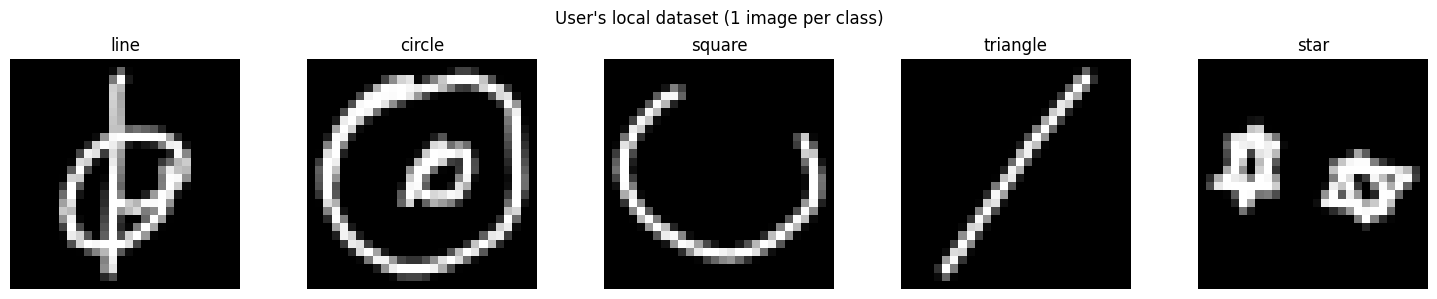

X_user shape: (5, 3, 224, 224)
y_user: [0, 1, 2, 3, 4]


In [6]:
download_quickdraw_dataset(
    root=DATA_DIR,
    file_names=sorted(set(GLOBAL_QUICKDRAW_FILE_NAMES)),
)
print(f"Available data files: {sorted(os.listdir(DATA_DIR))}")

data_config = {
    "input_size": (3, IMG_SIZE, IMG_SIZE),
    "mean": MEAN,
    "std": STD,
}
eval_transform = timm_data.create_transform(**data_config, is_training=False)
print(eval_transform)

if USER_SAMPLE_MODE == "hard":
    raw_images, local_labels, selected_indices = sample_hard_image_per_class(
        model=global_model,
        data_dir=DATA_DIR,
        class_names=USER_CLASS_NAMES,
        global_label_indices=USER_CLASS_INDICES,
        file_names_lookup=file_names_lookup,
        transform=eval_transform,
        candidates_per_class=HARD_SAMPLE_CANDIDATES_PER_CLASS,
        seed=SEED,
    )
else:
    raw_images, local_labels, selected_indices = sample_one_image_per_class(
        data_dir=DATA_DIR,
        class_names=USER_CLASS_NAMES,
        file_names_lookup=file_names_lookup,
        seed=SEED,
    )

global_labels = [USER_CLASS_INDICES[l] for l in local_labels]

print(f"Sampled {len(raw_images)} images, one per class.")
print(f"Selected raw-data indices: {selected_indices}")
print(f"Global label indices for this user's images: {global_labels}")

show_user_dataset(raw_images, USER_CLASS_NAMES)

X_user = preprocess_images(raw_images, eval_transform).to(DEVICE)
y_user = torch.tensor(global_labels, dtype=torch.long, device=DEVICE)

print(f"X_user shape: {tuple(X_user.shape)}")
print(f"y_user: {y_user.tolist()}")


## 6. Evaluate the received global model

Before local adaptation, we evaluate the server checkpoint on the five client images. This establishes the client's starting point and makes the local update interpretable: the update should respond to errors made by the global model on this user's data.


In [7]:
criterion = nn.CrossEntropyLoss()

before_loss, before_acc, before_preds = evaluate_local(global_model, X_user, y_user, criterion)
print(f"[Before local fine-tuning] loss: {before_loss:.4f} | acc: {before_acc:.2f}%")
print(f"Predictions: {[GLOBAL_CLASS_NAMES[p] for p in before_preds]}")
print(f"Ground truth: {USER_CLASS_NAMES}")


[Before local fine-tuning] loss: 5.4683 | acc: 0.00%
Predictions: ['star', 'donut', 'smiley_face', 'line', 'cloud']
Ground truth: ['line', 'circle', 'square', 'triangle', 'star']


## 7. Build the local client model

The local model is a copy of the received global model. Only the classifier weight and bias are trainable.

This is a personalization strategy for the current setup. Five samples are not enough to justify updating the full visual backbone. For the 10-class MobileNetV4 Small model used here, the classifier contains about **12.8K trainable parameters**, while the rest of the network remains frozen.

The code also identifies the exact state-dict keys of the classifier tensors. Those keys are later used to verify that no backbone tensor changed and to isolate the update observed by the server.


In [8]:
local_model = copy.deepcopy(global_model)
local_model.to(DEVICE)

classifier_module = local_model.get_classifier()
print(f"Classifier head module: {classifier_module}")

head_weight_key, head_bias_key = find_head_parameter_keys(local_model, classifier_module)
print(f"Classifier state-dict keys: {head_weight_key}, {head_bias_key}")

head_param_ids = {id(p) for p in classifier_module.parameters()}

n_frozen, n_trainable = 0, 0
for p in local_model.parameters():
    if id(p) in head_param_ids:
        p.requires_grad = True
        n_trainable += p.numel()
    else:
        p.requires_grad = False
        n_frozen += p.numel()

print(f"Frozen (backbone) params: {n_frozen:,}")
print(f"Trainable (head) params: {n_trainable:,}")
print(f"Trainable fraction: {100.0 * n_trainable / (n_frozen + n_trainable):.3f}%")
print(f"Raw FP32 head/update size: {n_trainable * 4 / (1024 ** 2):.4f} MiB")


Classifier head module: Linear(in_features=1280, out_features=10, bias=True)
Classifier state-dict keys: classifier.weight, classifier.bias
Frozen (backbone) params: 957,952
Trainable (head) params: 12,810
Trainable fraction: 1.320%
Raw FP32 head/update size: 0.0489 MiB


## 8. Perform one local SGD step and measure client cost

We use one SGD step because it gives a direct relationship between the transmitted model delta and the local gradient. Adam or multiple local steps would make the inverse mapping depend on optimizer state and the full optimization trajectory.

The model stays in `eval()` mode during the update. Freezing parameters with `requires_grad=False` is not enough to freeze BatchNorm running statistics if the model is placed in training mode.

The resource counters are reset immediately before local fine-tuning. We report both the absolute peak and the increase above the pre-training memory level.


Starting local head-only fine-tuning for 1 SGD step(s) on 5 local images...

[Local step 01/1] loss: 5.4683 | acc: 0.00%

Local fine-tuning complete.
Fine-tuning time: 0.0857 s
Peak process RAM (RSS): 1288.05 MiB (increase during fine-tuning: 39.14 MiB)
Peak CUDA VRAM allocated: 34.95 MiB (increase: 15.31 MiB)
Peak CUDA VRAM reserved:  690.00 MiB (increase: 2.00 MiB)
Captured first-step gradients for tensors: ['classifier.weight', 'classifier.bias']


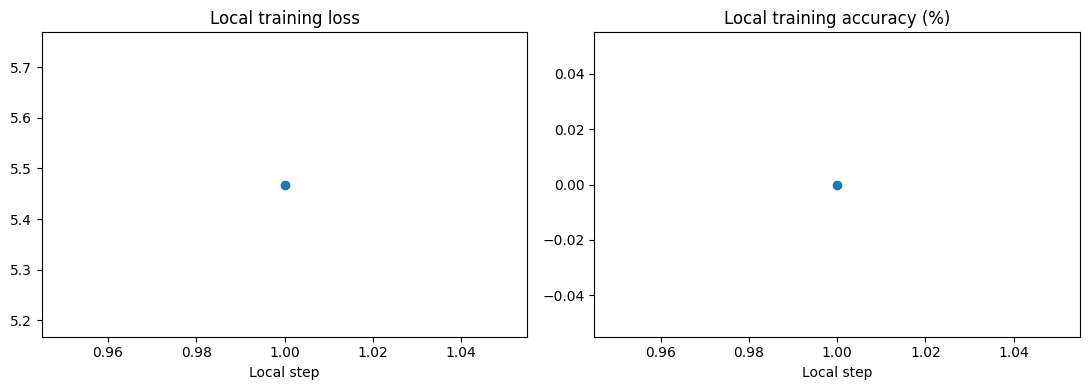

In [9]:
local_optimizer = torch.optim.SGD(
    [p for p in local_model.parameters() if p.requires_grad],
    lr=LOCAL_LR,
)

local_history = {"step": [], "loss": [], "acc": []}
first_step_grad_full = {}

print(
    f"Starting local head-only fine-tuning for {LOCAL_STEPS} SGD step(s) "
    f"on {len(USER_CLASS_NAMES)} local images...\n"
)

local_model.eval()

process = psutil.Process(os.getpid())
ram_at_start_bytes = process.memory_info().rss

if DEVICE.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    vram_at_start_allocated_bytes = torch.cuda.memory_allocated()
    vram_at_start_reserved_bytes = torch.cuda.memory_reserved()
else:
    vram_at_start_allocated_bytes = None
    vram_at_start_reserved_bytes = None

with PeakRAMMonitor() as ram_monitor:
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    finetune_start = time.perf_counter()

    for step in range(1, LOCAL_STEPS + 1):
        local_optimizer.zero_grad(set_to_none=True)

        logits = local_model(X_user)
        loss = criterion(logits, y_user)
        loss.backward()

        if step == 1:
            for name, p in local_model.named_parameters():
                if p.requires_grad:
                    first_step_grad_full[name] = p.grad.detach().clone()

        local_optimizer.step()

        with torch.no_grad():
            preds = logits.argmax(dim=1)
            acc = 100.0 * (preds == y_user).float().mean().item()

        local_history["step"].append(step)
        local_history["loss"].append(loss.item())
        local_history["acc"].append(acc)

        print(
            f"[Local step {step:02d}/{LOCAL_STEPS}] "
            f"loss: {loss.item():.4f} | acc: {acc:.2f}%"
        )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    finetune_time_seconds = time.perf_counter() - finetune_start

peak_process_ram_bytes = ram_monitor.peak_rss_bytes
peak_process_ram_mib = peak_process_ram_bytes / (1024 ** 2)
peak_process_ram_increase_mib = max(
    0.0,
    (peak_process_ram_bytes - ram_at_start_bytes) / (1024 ** 2),
)

if DEVICE.type == "cuda":
    peak_cuda_allocated_bytes = torch.cuda.max_memory_allocated()
    peak_cuda_reserved_bytes = torch.cuda.max_memory_reserved()
    peak_cuda_allocated_mib = peak_cuda_allocated_bytes / (1024 ** 2)
    peak_cuda_reserved_mib = peak_cuda_reserved_bytes / (1024 ** 2)
    cuda_allocated_increase_mib = max(
        0.0,
        (peak_cuda_allocated_bytes - vram_at_start_allocated_bytes) / (1024 ** 2),
    )
    cuda_reserved_increase_mib = max(
        0.0,
        (peak_cuda_reserved_bytes - vram_at_start_reserved_bytes) / (1024 ** 2),
    )
else:
    peak_cuda_allocated_mib = None
    peak_cuda_reserved_mib = None
    cuda_allocated_increase_mib = None
    cuda_reserved_increase_mib = None

print("\nLocal fine-tuning complete.")
print(f"Fine-tuning time: {finetune_time_seconds:.4f} s")
print(
    f"Peak process RAM (RSS): {peak_process_ram_mib:.2f} MiB "
    f"(increase during fine-tuning: {peak_process_ram_increase_mib:.2f} MiB)"
)

if DEVICE.type == "cuda":
    print(
        f"Peak CUDA VRAM allocated: {peak_cuda_allocated_mib:.2f} MiB "
        f"(increase: {cuda_allocated_increase_mib:.2f} MiB)"
    )
    print(
        f"Peak CUDA VRAM reserved:  {peak_cuda_reserved_mib:.2f} MiB "
        f"(increase: {cuda_reserved_increase_mib:.2f} MiB)"
    )
else:
    print("Peak CUDA VRAM: N/A because CUDA is not active.")

print(f"Captured first-step gradients for tensors: {list(first_step_grad_full.keys())}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(local_history["step"], local_history["loss"], marker="o")
axes[0].set_title("Local training loss")
axes[0].set_xlabel("Local step")

axes[1].plot(local_history["step"], local_history["acc"], marker="o")
axes[1].set_title("Local training accuracy (%)")
axes[1].set_xlabel("Local step")

plt.tight_layout()
plt.show()


## 9. Evaluate the local model and construct the uploaded update

After local adaptation, we compare performance before and after the client step,

Because the backbone is frozen, only the classifier weight and bias are expected to change.

We save both the full local checkpoint and the delta. In a real FL deployment the protocol may transmit an update, compressed update, secure aggregation contribution, or another representation. Here the explicit delta keeps the privacy experiment transparent.


In [10]:
after_loss, after_acc, after_preds = evaluate_local(local_model, X_user, y_user, criterion)
print(f"[After local fine-tuning] loss: {after_loss:.4f} | acc: {after_acc:.2f}%")
print(f"Predictions: {[GLOBAL_CLASS_NAMES[p] for p in after_preds]}")
print(f"Ground truth: {USER_CLASS_NAMES}")

print("\nBefore -> After")
print(f"Loss:     {before_loss:.4f} -> {after_loss:.4f}")
print(f"Accuracy: {before_acc:.2f}% -> {after_acc:.2f}%")

theta_local = {
    k: v.detach().cpu().clone()
    for k, v in local_model.state_dict().items()
}

delta = {}
nonzero_keys = []
for k in theta_global:
    diff = theta_local[k] - theta_global[k]
    delta[k] = diff
    if torch.any(diff != 0):
        nonzero_keys.append(k)

print(f"\nTotal parameter tensors: {len(delta)}")
print(f"Tensors with a nonzero update: {len(nonzero_keys)}")
print(f"Nonzero tensors: {nonzero_keys}")

assert set(nonzero_keys) == {head_weight_key, head_bias_key}, (
    "Expected exactly the classifier weight and bias to change under head-only fine-tuning. "
    f"Expected {{{head_weight_key}, {head_bias_key}}}, got {nonzero_keys}. "
    "If this fails, check that the backbone was frozen and local_model.eval() was used."
)

local_ckpt_path = OUTPUT_DIR / "user1_local_model.safetensors"
save_safetensors({k: v.contiguous() for k, v in theta_local.items()}, str(local_ckpt_path))
print(f"Saved local model to: {local_ckpt_path}")

delta_ckpt_path = OUTPUT_DIR / "user1_update_delta.safetensors"
save_safetensors({k: v.contiguous() for k, v in delta.items()}, str(delta_ckpt_path))
print(f"Saved update delta to: {delta_ckpt_path}")

user_metadata = {
    "user_id": "user1",
    "n_local_samples": len(USER_CLASS_NAMES),
    "finetune_strategy": "head_only",
    "optimizer": "SGD",
    "local_steps": LOCAL_STEPS,
    "local_lr": LOCAL_LR,
    "finetune_time_seconds": finetune_time_seconds,
    "peak_process_ram_mib": peak_process_ram_mib,
    "peak_process_ram_increase_mib": peak_process_ram_increase_mib,
    "peak_cuda_allocated_mib": peak_cuda_allocated_mib,
    "peak_cuda_reserved_mib": peak_cuda_reserved_mib,
    "cuda_allocated_increase_mib": cuda_allocated_increase_mib,
    "cuda_reserved_increase_mib": cuda_reserved_increase_mib,
    "total_model_params": total_model_params,
    "trainable_head_params": n_trainable,
    "sample_mode": USER_SAMPLE_MODE,
    "stage1_checkpoint": str(STAGE1_CKPT_PATH),
    "global_label_space": GLOBAL_CLASS_NAMES,
    "before_local_finetune": {"loss": before_loss, "accuracy": before_acc},
    "after_local_finetune": {"loss": after_loss, "accuracy": after_acc},
    "nonzero_update_tensors": nonzero_keys,
    # Ground truth is kept for evaluation only. A real attacker does not have this field.
    "ground_truth_local_classes": USER_CLASS_NAMES,
    "ground_truth_global_label_indices": global_labels,
    "selected_raw_data_indices": selected_indices,
}

metadata_path = OUTPUT_DIR / "user1_metadata.json"
with open(metadata_path, "w") as f:
    json.dump(user_metadata, f, indent=2)
print(f"Saved user metadata to: {metadata_path}")


[After local fine-tuning] loss: 2.8258 | acc: 20.00%
Predictions: ['star', 'circle', 'smiley_face', 'line', 'cloud']
Ground truth: ['line', 'circle', 'square', 'triangle', 'star']

Before -> After
Loss:     5.4683 -> 2.8258
Accuracy: 0.00% -> 20.00%

Total parameter tensors: 278
Tensors with a nonzero update: 2
Nonzero tensors: ['classifier.weight', 'classifier.bias']
Saved local model to: outputs_user1/user1_local_model.safetensors
Saved update delta to: outputs_user1/user1_update_delta.safetensors
Saved user metadata to: outputs_user1/user1_metadata.json


## 10. Server view: recover the first-step gradient from the uploaded delta

The server is assumed to know the global model, the client learning rate, and the uploaded model delta. It does not receive the private images or labels.

The attack reconstructs the classifier gradient from the transmitted update itself.

For this controlled experiment we also retained the private in-memory gradient inside the client simulation. It is used only for a numerical sanity check that the delta-derived gradient is correct. A real server would not have that second copy.


In [11]:
# Threat model: the server does not receive `first_step_grad_full`. It receives only the
# model update delta. Because we intentionally used exactly one SGD step:
#
#   theta_local = theta_global - lr * grad
#   delta       = theta_local - theta_global
#   grad        = -delta / lr
#
# This section is therefore closer to the real FL artifact than directly exposing the
# in-memory gradient tensor.

attack_global_model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=NUM_GLOBAL_CLASSES,
)
attack_global_model.load_state_dict(theta_global)
attack_global_model.to(DEVICE)
attack_global_model.eval()

for p in attack_global_model.parameters():
    p.requires_grad = False

attack_classifier = attack_global_model.get_classifier()
W_global = attack_classifier.weight.detach().clone().to(DEVICE)
b_global = attack_classifier.bias.detach().clone().to(DEVICE)

embed_dim = W_global.shape[1]
N_SAMPLES = user_metadata["n_local_samples"]

target_grad_W = (-delta[head_weight_key].to(DEVICE) / LOCAL_LR).detach()
target_grad_b = (-delta[head_bias_key].to(DEVICE) / LOCAL_LR).detach()

print(f"\nFrozen global head: W shape {tuple(W_global.shape)}, b shape {tuple(b_global.shape)}")
print(f"Attacker knows: n_local_samples = {N_SAMPLES}")
print("Attacker reconstructs target_grad_W and target_grad_b from the uploaded delta.")

# Sanity check only. This compares the attacker's delta-derived gradient against the private
# gradient we captured during simulation. In a real attack we would not have this reference.
sanity_grad_w_mse = F.mse_loss(target_grad_W, first_step_grad_full[head_weight_key].to(DEVICE)).item()
sanity_grad_b_mse = F.mse_loss(target_grad_b, first_step_grad_full[head_bias_key].to(DEVICE)).item()
print(f"Sanity check grad_W MSE(delta-derived vs captured): {sanity_grad_w_mse:.12f}")
print(f"Sanity check grad_b MSE(delta-derived vs captured): {sanity_grad_b_mse:.12f}")



Frozen global head: W shape (10, 1280), b shape (10,)
Attacker knows: n_local_samples = 5
Attacker reconstructs target_grad_W and target_grad_b from the uploaded delta.
Sanity check grad_W MSE(delta-derived vs captured): 0.000000000000
Sanity check grad_b MSE(delta-derived vs captured): 0.000000000000


## 11. Attack stage 1: recover the client's label set

A simple rule is to inspect the most negative bias-gradient entries, but that can fail when the global model is already confident or strongly confuses one class with another.

For this 10-class, 5-sample demonstration, we can enumerate all possible distinct label sets. Each set is scored using the bias-gradient evidence plus a small classifier-row-norm term. Exhaustive enumeration is practical here and avoids pretending that a single per-class heuristic is universally reliable.

The true label set is used only after recovery to evaluate the attack.


In [12]:
# For a linear classifier head, the observed gradient is:
#
#   grad_b[c] = mean_i(p_i[c] - 1[y_i = c])
#   grad_W[c] = mean_i((p_i[c] - 1[y_i = c]) * h_i)
#
# where h_i is the frozen-backbone embedding of sample i. The classic quick heuristic is to
# take the N most negative entries of grad_b. That heuristic is useful, but it is NOT exact
# once the global model is already confident: a true class can have a small positive bias
# gradient, and a non-user class can have a large positive gradient if the model assigns it
# probability mass as a confusable alternative.
#
# We score COMPLETE label sets instead of selecting labels
# independently. For each candidate set S of size N, we use:
#
#   score(S) = -sum_c in S grad_b[c] + lambda * sum_c in S ||grad_W[c]||_2
#
# The first term favors labels whose bias-gradient contribution looks like a target class. It
# also strongly penalizes large positive-bias confuser classes such as "sun" in the example
# where the true class is "star". The second term is intentionally SMALL: it helps recover
# true classes such as line/square whose bias entries can be slightly positive, but it should
# not dominate the bias evidence.
#
# This is still a heuristic, not a proof of identifiability. With only a head-only update from
# an already well-trained model, some label sets can be genuinely ambiguous. That ambiguity is
# itself a useful FL privacy lesson: the head update leaks useful class information, but the
# leakage strength depends heavily on the magnitude and structure of the gradient.

print("\nBias gradient sorted from most negative to most positive:")
sorted_by_bias = torch.argsort(target_grad_b).tolist()
for c in sorted_by_bias:
    print(f"{c:2d} {GLOBAL_CLASS_NAMES[c]:15s} {target_grad_b[c].item():+.8f}")

bias_top_indices = sorted_by_bias[:N_SAMPLES]
bias_top_names = [GLOBAL_CLASS_NAMES[c] for c in bias_top_indices]
print("\nNaive top-N bias-gradient label set:")
print(bias_top_indices, bias_top_names)

row_norms = target_grad_W.flatten(1).norm(dim=1)

print("\nPer-class gradient evidence:")
for c in range(NUM_GLOBAL_CLASSES):
    print(
        f"{c:2d} {GLOBAL_CLASS_NAMES[c]:15s} "
        f"bias={target_grad_b[c].item():+.8f} | "
        f"row_norm={row_norms[c].item():.8f}"
    )

# Enumerate all possible distinct label sets. For the current example this is
# only C(10, 5) = 252 sets, so exhaustive enumeration is simpler and more robust than a greedy
# or coordinate-descent label search.
combo_scores = []
for combo in combinations(range(NUM_GLOBAL_CLASSES), N_SAMPLES):
    combo = tuple(combo)
    bias_sum = float(target_grad_b[list(combo)].sum().item())
    row_sum = float(row_norms[list(combo)].sum().item())
    score = -bias_sum + LABEL_SET_ROW_NORM_WEIGHT * row_sum
    combo_scores.append((score, bias_sum, row_sum, combo))

combo_scores.sort(key=lambda x: x[0], reverse=True)

best_label_score, best_bias_sum, best_row_sum, best_combo = combo_scores[0]
recovered_label_indices = list(best_combo)
recovered_label_names = [GLOBAL_CLASS_NAMES[c] for c in recovered_label_indices]

true_label_set = set(global_labels)
recovered_label_set = set(recovered_label_indices)
label_set_acc = 100.0 * len(true_label_set.intersection(recovered_label_set)) / N_SAMPLES

print("\nTop label-set candidates by bias-sum + small row-norm score:")
for rank, (score, bias_sum, row_sum, combo) in enumerate(combo_scores[:LABEL_SET_TOP_K_TO_PRINT], start=1):
    names = [GLOBAL_CLASS_NAMES[c] for c in combo]
    marker = " <-- true set (evaluation only)" if set(combo) == true_label_set else ""
    print(
        f"{rank:02d}. score={score:+.6f} | "
        f"bias_sum={bias_sum:+.8f} | row_norm_sum={row_sum:.8f} | "
        f"labels={names}{marker}"
    )

# If the true set is not in the printed top-K, print its rank for debugging. This uses ground
# truth and must be read as evaluation-only, not as information available to the attacker.
true_combo = tuple(sorted(global_labels))
true_rank = None
for idx, (_, _, _, combo) in enumerate(combo_scores, start=1):
    if tuple(sorted(combo)) == true_combo:
        true_rank = idx
        break
if true_rank is not None and true_rank > LABEL_SET_TOP_K_TO_PRINT:
    score, bias_sum, row_sum, combo = combo_scores[true_rank - 1]
    names = [GLOBAL_CLASS_NAMES[c] for c in combo]
    print(
        f"True label set rank (evaluation only): {true_rank}/{len(combo_scores)} | "
        f"score={score:+.6f} | bias_sum={bias_sum:+.8f} | "
        f"row_norm_sum={row_sum:.8f} | labels={names}"
    )

print("\nRecovered label set:")
print(recovered_label_indices, recovered_label_names)
print(f"\nLabel set recovery accuracy: {label_set_acc:.1f}% (n={N_SAMPLES})")

# The reconstructions below are generated in recovered-label order. Sorting the recovered
# labels keeps runs deterministic and makes the paired-by-label plot easier to read.
recovered_label_indices = sorted(recovered_label_indices)
recovered_label_names = [GLOBAL_CLASS_NAMES[c] for c in recovered_label_indices]



Bias gradient sorted from most negative to most positive:
 2 square          -0.17647794
 3 triangle        -0.13538934
 1 circle          -0.10247789
 4 star            -0.07433453
 7 sun             +0.00379574
 0 line            +0.00493033
 5 tshirt          +0.01760353
 8 cloud           +0.08000597
 6 smiley_face     +0.16177115
 9 donut           +0.22057290

Naive top-N bias-gradient label set:
[2, 3, 1, 4, 7] ['square', 'triangle', 'circle', 'star', 'sun']

Per-class gradient evidence:
 0 line            bias=+0.00493033 | row_norm=1.45414650
 1 circle          bias=-0.10247789 | row_norm=12.89075851
 2 square          bias=-0.17647794 | row_norm=1.22033000
 3 triangle        bias=-0.13538934 | row_norm=1.23261487
 4 star            bias=-0.07433453 | row_norm=0.79237705
 5 tshirt          bias=+0.01760353 | row_norm=0.08631432
 6 smiley_face     bias=+0.16177115 | row_norm=0.81967223
 7 sun             bias=+0.00379574 | row_norm=0.01435554
 8 cloud           bias=+0.0800059

## 12. Attack stage 2: reconstruct images from the observed head gradient

Label leakage is only part of the privacy story. We next ask whether the observed classifier gradient can also constrain the client's pixels.

The attack optimizes five 28×28 grayscale canvases directly. Each candidate image is mapped through the same preprocessing pipeline and frozen MobileNetV4 backbone, then the resulting classifier gradient is compared with the gradient reconstructed from the client's uploaded delta.

Directly optimizing the 28×28 canvas keeps the search in the same low-dimensional image space as QuickDraw. The objective combines gradient matching with mild total-variation, sparsity, and binarization priors.

The default initialization uses a **public class prior**: an unrelated public QuickDraw example from the recovered class. This does not use the client's private image, but it gives the optimizer a class-plausible starting point. The notebook also runs an optional oracle experiment with the true labels.


In [13]:
# Here we optimize the images directly. To make the inverse problem much better posed, the
# variables are constrained to a 28x28 grayscale QuickDraw canvas. Each candidate canvas is:
#   1. squashed through sigmoid to valid [0, 1] pixels,
#   2. resized to the model input size,
#   3. repeated to 3 channels,
#   4. normalized with the Stage 1 mean/std,
#   5. passed through the frozen backbone and classifier head.
#
# Implementation details:
#   - reconstructions are paired by recovered label for evaluation;
#   - an oracle true-label reconstruction is run as an upper-bound diagnostic;
#   - the default initialization uses public QuickDraw class priors instead of pure black
#     noise. This often makes reconstructions more class-plausible, while still not using the
#     user's private image as initialization.

mean_t = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
std_t = torch.tensor(STD, device=DEVICE).view(1, 3, 1, 1)


def canvas_to_model_input(canvas_logits: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
    """Map unconstrained 28x28 logits to normalized 3-channel model input."""
    gray_28 = torch.sigmoid(canvas_logits)

    gray_big = F.interpolate(
        gray_28,
        size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear",
        align_corners=False,
    )

    img3 = gray_big.repeat(1, 3, 1, 1)
    x_norm = (img3 - mean_t) / std_t

    return x_norm, gray_28


def grad_match_loss_from_canvas(
    canvas_logits: torch.Tensor,
    labels_tensor: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Compute direct image attack loss and diagnostic terms."""
    x_norm, gray_28 = canvas_to_model_input(canvas_logits)

    # W_req and b_req are temporary leaf variables. We ask autograd for the gradient of
    # cross-entropy w.r.t. these head parameters, then backpropagate the mismatch all the way
    # to the canvas pixels through the frozen backbone.
    W_req = W_global.clone().detach().requires_grad_(True)
    b_req = b_global.clone().detach().requires_grad_(True)

    emb = embedding_of(attack_global_model, x_norm)
    logits = emb @ W_req.t() + b_req
    ce = F.cross_entropy(logits, labels_tensor)

    gW, gb = torch.autograd.grad(
        ce,
        [W_req, b_req],
        create_graph=True,
    )

    # Normalize the two gradient losses so that tuning is less sensitive to absolute scale.
    w_loss = F.mse_loss(gW, target_grad_W) / (target_grad_W.pow(2).mean().detach() + 1e-12)
    b_loss = F.mse_loss(gb, target_grad_b) / (target_grad_b.pow(2).mean().detach() + 1e-12)
    grad_loss = w_loss + GRAD_B_WEIGHT * b_loss

    tv_loss = (
        (gray_28[:, :, 1:, :] - gray_28[:, :, :-1, :]).abs().mean()
        + (gray_28[:, :, :, 1:] - gray_28[:, :, :, :-1]).abs().mean()
    )

    # QuickDraw sketches are mostly black background with sparse white strokes.
    sparsity_loss = gray_28.mean()

    # Encourage pixels to move toward 0 or 1 instead of staying gray everywhere.
    binary_loss = (gray_28 * (1.0 - gray_28)).mean()

    total_loss = (
        grad_loss
        + TV_WEIGHT * tv_loss
        + SPARSITY_WEIGHT * sparsity_loss
        + BINARY_WEIGHT * binary_loss
    )

    return total_loss, grad_loss, tv_loss, sparsity_loss, binary_loss, gray_28


def raw28_to_canvas_logits(raw_img: np.ndarray, eps: float = PUBLIC_PRIOR_LOGIT_EPS) -> torch.Tensor:
    """Convert a raw 28x28 QuickDraw image in 0..255 scale to canvas logits."""
    gray = torch.tensor(raw_img.astype(np.float32) / 255.0, dtype=torch.float32)
    gray = gray.clamp(eps, 1.0 - eps)
    logits = torch.log(gray / (1.0 - gray))
    return logits.view(1, 28, 28)


def sample_public_prior_image_for_label(label_idx: int, rng: np.random.Generator) -> Tuple[np.ndarray, int]:
    """Sample one public QuickDraw image for a class prior.

    The user images are sampled from indices >= 20000 in this notebook. By default, the public
    prior is sampled from earlier indices. This avoids accidentally initializing from exactly
    the user's private sample, while still representing a realistic attacker that can use
    public examples of the same class.
    """
    cls = GLOBAL_CLASS_NAMES[label_idx]
    fname = file_names_lookup[cls]
    fpath = DATA_DIR / f"{fname}.npy"
    data = np.load(fpath, mmap_mode="r")

    upper = min(PUBLIC_PRIOR_INDEX_MAX, data.shape[0])
    if upper <= 0:
        raise RuntimeError(f"No public prior candidates found for label '{cls}'.")

    idx = int(rng.integers(0, upper))
    img = np.array(data[idx]).reshape(28, 28).astype(np.uint8)
    return img, idx


def initialize_canvas_logits(
    label_indices: List[int],
    restart: int,
    init_mode: str,
) -> Tuple[torch.Tensor, List[Optional[int]], Optional[np.ndarray]]:
    """Initialize attack canvases either from black noise or public class priors."""
    torch.manual_seed(SEED + 1000 + restart)

    if init_mode == "black_noise":
        canvas_logits = (
            CANVAS_INIT_LOGIT
            + CANVAS_INIT_NOISE * torch.randn(len(label_indices), 1, 28, 28, device=DEVICE)
        )
        return canvas_logits.requires_grad_(True), [None] * len(label_indices), None

    if init_mode != "public_class_prior":
        raise ValueError(f"Unknown PIXEL_INIT_MODE='{init_mode}'.")

    rng = np.random.default_rng(SEED + 5000 + restart)
    prior_imgs, prior_indices, prior_logits = [], [], []

    for label_idx in label_indices:
        prior_img, prior_idx = sample_public_prior_image_for_label(label_idx, rng)
        prior_imgs.append(prior_img)
        prior_indices.append(prior_idx)
        prior_logits.append(raw28_to_canvas_logits(prior_img))

    canvas_logits = torch.stack(prior_logits, dim=0).to(DEVICE)
    canvas_logits = canvas_logits + PUBLIC_PRIOR_NOISE * torch.randn_like(canvas_logits)

    return canvas_logits.requires_grad_(True), prior_indices, np.stack(prior_imgs)


def run_direct_canvas_attack(
    label_indices: List[int],
    attack_name: str,
    init_mode: str = PIXEL_INIT_MODE,
) -> Dict:
    """Run the direct 28x28 gradient-matching attack for a given label set."""
    label_indices = list(label_indices)
    label_names = [GLOBAL_CLASS_NAMES[c] for c in label_indices]
    labels_tensor = torch.tensor(label_indices, dtype=torch.long, device=DEVICE)

    best_restart = None
    restart_results = []

    print(
        f"\nRunning {attack_name}: {PIXEL_ATTACK_RESTARTS} restart(s), "
        f"{PIXEL_ATTACK_STEPS} step(s) each, init='{init_mode}'."
    )
    print(f"Labels for this reconstruction: {label_indices} {label_names}\n")

    for restart in range(PIXEL_ATTACK_RESTARTS):
        canvas_logits, prior_indices, prior_imgs = initialize_canvas_logits(
            label_indices=label_indices,
            restart=restart,
            init_mode=init_mode,
        )

        pixel_optimizer = torch.optim.Adam([canvas_logits], lr=PIXEL_ATTACK_LR)
        history = {"step": [], "total": [], "grad": [], "tv": [], "sparsity": [], "binary": []}

        for step in range(1, PIXEL_ATTACK_STEPS + 1):
            pixel_optimizer.zero_grad(set_to_none=True)

            total_loss, grad_loss, tv_loss, sparsity_loss, binary_loss, gray_28 = grad_match_loss_from_canvas(
                canvas_logits,
                labels_tensor,
            )

            total_loss.backward()
            pixel_optimizer.step()

            if step % 100 == 0 or step == 1 or step == PIXEL_ATTACK_STEPS:
                history["step"].append(step)
                history["total"].append(float(total_loss.item()))
                history["grad"].append(float(grad_loss.item()))
                history["tv"].append(float(tv_loss.item()))
                history["sparsity"].append(float(sparsity_loss.item()))
                history["binary"].append(float(binary_loss.item()))

            if step % 250 == 0 or step == 1 or step == PIXEL_ATTACK_STEPS:
                print(
                    f"[{attack_name} | restart {restart + 1}/{PIXEL_ATTACK_RESTARTS} | "
                    f"step {step:04d}/{PIXEL_ATTACK_STEPS}] "
                    f"total={total_loss.item():.6f} | grad={grad_loss.item():.6f} | "
                    f"tv={tv_loss.item():.6f} | sparse={sparsity_loss.item():.6f} | "
                    f"binary={binary_loss.item():.6f}"
                )

        # Do not wrap this call in torch.no_grad(): grad_match_loss_from_canvas internally
        # calls torch.autograd.grad to compare the simulated and observed head gradients. It
        # still needs autograd enabled even though we do not call backward() here.
        final_total, final_grad, final_tv, final_sparsity, final_binary, final_gray_28 = grad_match_loss_from_canvas(
            canvas_logits,
            labels_tensor,
        )

        result = {
            "restart": restart,
            "final_total": float(final_total.item()),
            "final_grad": float(final_grad.item()),
            "final_tv": float(final_tv.item()),
            "final_sparsity": float(final_sparsity.item()),
            "final_binary": float(final_binary.item()),
            "gray_28": final_gray_28.detach().cpu(),
            "history": history,
            "public_prior_indices": prior_indices,
            "public_prior_images": prior_imgs,
        }
        restart_results.append(result)

        if best_restart is None or result["final_grad"] < best_restart["final_grad"]:
            best_restart = result

    print(
        f"\nBest {attack_name} restart: {best_restart['restart']} "
        f"| final_total={best_restart['final_total']:.6f} "
        f"| final_grad={best_restart['final_grad']:.6f}"
    )

    return {
        "attack_name": attack_name,
        "label_indices": label_indices,
        "label_names": label_names,
        "best_restart": best_restart,
        "restart_results": restart_results,
        "reconstructed_gray_28": best_restart["gray_28"].squeeze(1).numpy(),
    }


# Main attacker reconstruction: use the recovered label set only.
recovered_attack = run_direct_canvas_attack(
    label_indices=recovered_label_indices,
    attack_name="recovered-label attack",
    init_mode=PIXEL_INIT_MODE,
)
reconstructed_gray_28 = recovered_attack["reconstructed_gray_28"]

# Oracle reconstruction: use true labels only for evaluation/diagnostics.
# If oracle labels still produce weak images, the bottleneck is not label recovery; it is the
# limited spatial information available in a one-step head-only update.
oracle_attack = None
if RUN_ORACLE_TRUE_LABEL_RECONSTRUCTION:
    oracle_attack = run_direct_canvas_attack(
        label_indices=global_labels,
        attack_name="oracle true-label attack (evaluation only)",
        init_mode=PIXEL_INIT_MODE,
    )



Running recovered-label attack: 5 restart(s), 2500 step(s) each, init='public_class_prior'.
Labels for this reconstruction: [0, 1, 2, 3, 4] ['line', 'circle', 'square', 'triangle', 'star']

[recovered-label attack | restart 1/5 | step 0001/2500] total=10.866957 | grad=10.864730 | tv=0.204062 | sparse=0.142105 | binary=0.044240
[recovered-label attack | restart 1/5 | step 0250/2500] total=0.079560 | grad=0.076891 | tv=0.246679 | sparse=0.152520 | binary=0.050030
[recovered-label attack | restart 1/5 | step 0500/2500] total=0.036415 | grad=0.033762 | tv=0.244875 | sparse=0.154125 | binary=0.050916
[recovered-label attack | restart 1/5 | step 0750/2500] total=0.029163 | grad=0.026519 | tv=0.243743 | sparse=0.154835 | binary=0.051467
[recovered-label attack | restart 1/5 | step 1000/2500] total=0.026442 | grad=0.023803 | tv=0.243176 | sparse=0.155524 | binary=0.052004
[recovered-label attack | restart 1/5 | step 1250/2500] total=0.024644 | grad=0.022006 | tv=0.242865 | sparse=0.156247 | b

## 13. Visualize the reconstructions

Recovered images are paired with ground-truth images by class label for evaluation. We do not compare arbitrary reconstruction slots with arbitrary client-image slots because the gradient objective does not encode a meaningful slot order.

The oracle reconstruction, when enabled, is shown separately and clearly marked as evaluation-only.


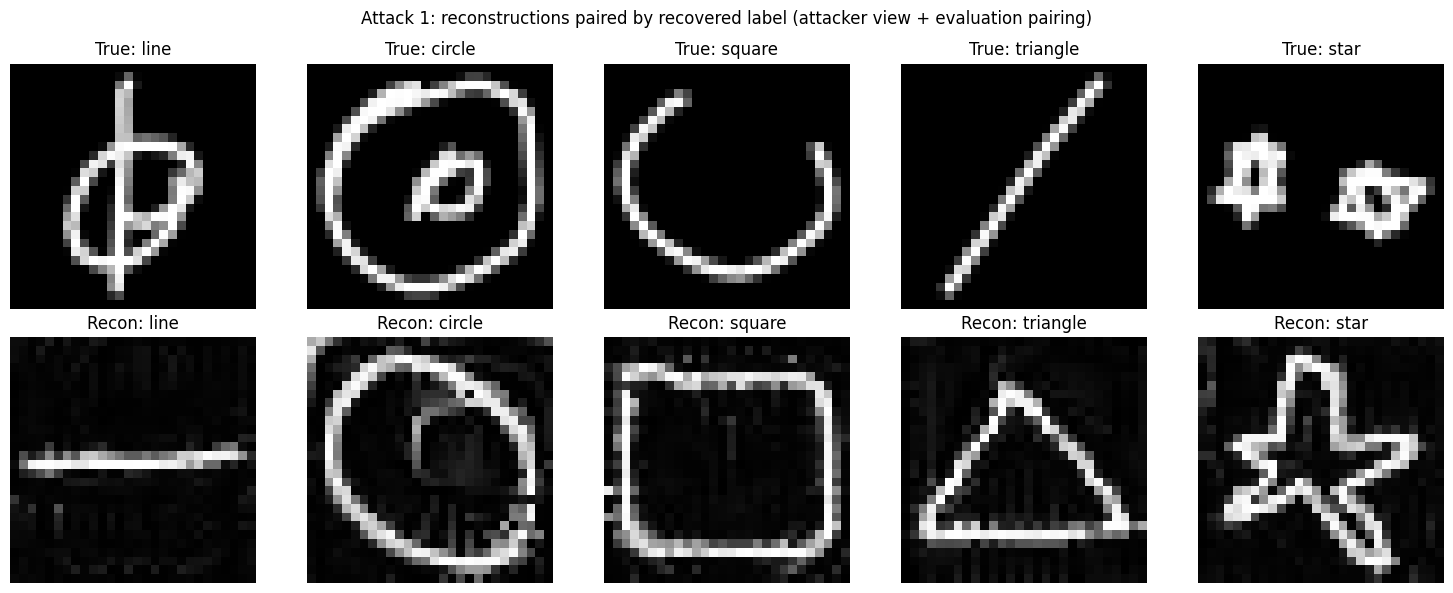

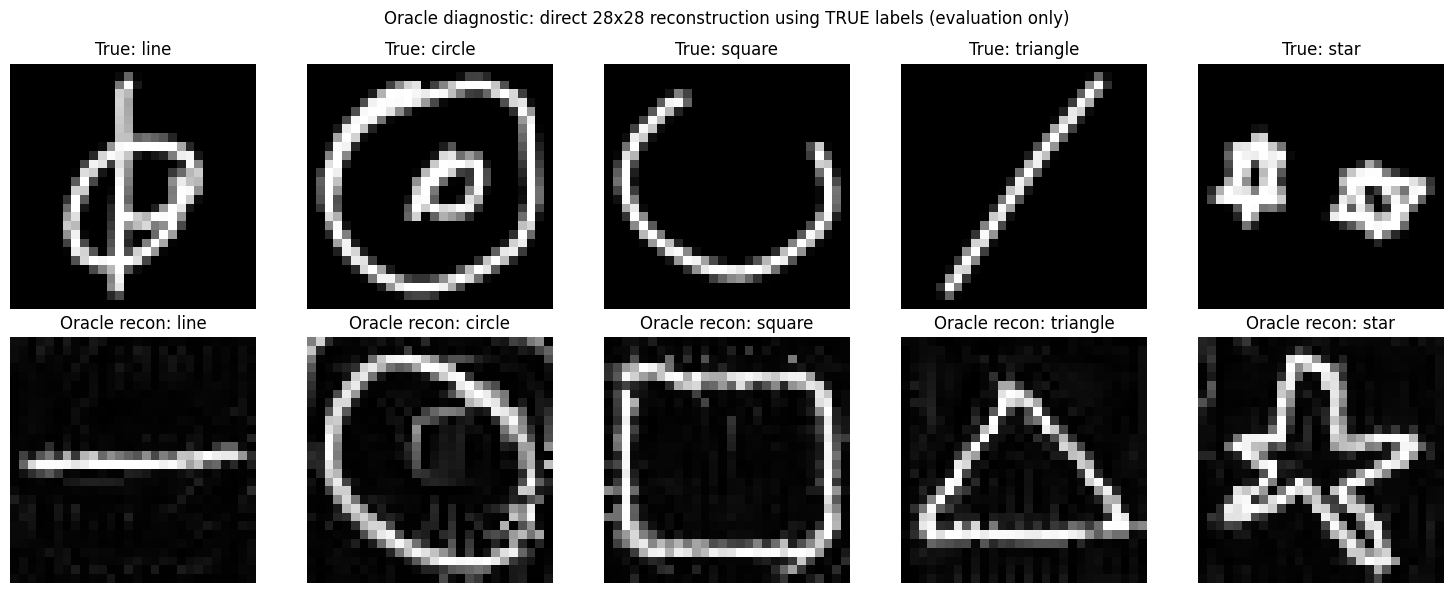

In [14]:
# We deliberately do NOT show a true-order-vs-recovered-order plot anymore, because that plot
# is misleading when the recovered label set is correct but ordered differently, or when one
# class is missing and one extra class is recovered.

true_image_by_label = {
    label: raw_img
    for label, raw_img in zip(global_labels, raw_images)
}


def plot_reconstructions_paired_by_label(attack: Dict, title: str) -> None:
    """Display each reconstructed image under the true image of the same label if present."""
    label_indices = attack["label_indices"]
    recon_gray = attack["reconstructed_gray_28"]
    n_cols = len(label_indices)

    fig, axes = plt.subplots(2, n_cols, figsize=(3 * n_cols, 6))
    if n_cols == 1:
        axes = np.array([[axes[0]], [axes[1]]])

    for i, label_idx in enumerate(label_indices):
        if label_idx in true_image_by_label:
            axes[0, i].imshow(true_image_by_label[label_idx], cmap="gray")
            axes[0, i].set_title(f"True: {GLOBAL_CLASS_NAMES[label_idx]}")
        else:
            axes[0, i].imshow(np.zeros((28, 28), dtype=np.uint8), cmap="gray")
            axes[0, i].set_title("True: not in user data")

        axes[0, i].axis("off")
        axes[1, i].imshow(recon_gray[i], cmap="gray", vmin=0, vmax=1)
        axes[1, i].set_title(f"Recon: {GLOBAL_CLASS_NAMES[label_idx]}")
        axes[1, i].axis("off")

    axes[0, 0].set_ylabel("Matched truth", fontsize=10)
    axes[1, 0].set_ylabel("Reconstructed", fontsize=10)
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_oracle_true_order(attack: Dict, title: str) -> None:
    """Display oracle reconstructions in the user's true local order."""
    recon_gray = attack["reconstructed_gray_28"]

    fig, axes = plt.subplots(2, N_SAMPLES, figsize=(3 * N_SAMPLES, 6))
    if N_SAMPLES == 1:
        axes = np.array([[axes[0]], [axes[1]]])

    for i, label_idx in enumerate(global_labels):
        axes[0, i].imshow(raw_images[i], cmap="gray")
        axes[0, i].set_title(f"True: {GLOBAL_CLASS_NAMES[label_idx]}")
        axes[0, i].axis("off")

        axes[1, i].imshow(recon_gray[i], cmap="gray", vmin=0, vmax=1)
        axes[1, i].set_title(f"Oracle recon: {GLOBAL_CLASS_NAMES[label_idx]}")
        axes[1, i].axis("off")

    axes[0, 0].set_ylabel("Ground truth", fontsize=10)
    axes[1, 0].set_ylabel("Oracle recon", fontsize=10)
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_reconstructions_paired_by_label(
    recovered_attack,
    "Attack 1: reconstructions paired by recovered label (attacker view + evaluation pairing)",
)

if oracle_attack is not None:
    plot_oracle_true_order(
        oracle_attack,
        "Oracle diagnostic: direct 28x28 reconstruction using TRUE labels (evaluation only)",
    )


## 14. Quantify reconstruction quality

For classes that exist in both the recovered label set and the private client dataset, we report MSE, PSNR, and a lightweight SSIM-style diagnostic.

These metrics are evaluation tools for the notebook. They are not available to the attacker because computing them requires the private ground-truth images.


In [15]:
def evaluate_reconstruction_by_label(attack: Dict, title: str) -> Tuple[List[Dict], List[float], List[float], List[float]]:
    """Evaluate reconstructions only when a recovered label exists in the user's data."""
    label_indices = attack["label_indices"]
    recon_gray = attack["reconstructed_gray_28"]

    print(f"\n{title}")
    print(f"{'Recovered label':<18} {'Has true?':>10} {'MSE':>10} {'PSNR (dB)':>12} {'SSIM':>10}")

    mses, psnrs, ssims = [], [], []
    per_image_results = []

    for i, label_idx in enumerate(label_indices):
        recon_img_255 = (recon_gray[i] * 255.0).clip(0, 255).astype(np.uint8)

        if label_idx in true_image_by_label:
            true_img = true_image_by_label[label_idx]
            mse = compute_mse(recon_img_255, true_img)
            psnr = compute_psnr(mse)
            ssim = compute_simple_ssim(recon_img_255, true_img)

            mses.append(mse)
            psnrs.append(psnr)
            ssims.append(ssim)

            print(
                f"{GLOBAL_CLASS_NAMES[label_idx]:<18} {'yes':>10} "
                f"{mse:>10.2f} {psnr:>12.2f} {ssim:>10.3f}"
            )

            per_image_results.append({
                "recovered_label": GLOBAL_CLASS_NAMES[label_idx],
                "has_matching_true_image": True,
                "mse": mse,
                "psnr_db": psnr,
                "ssim": ssim,
            })
        else:
            print(
                f"{GLOBAL_CLASS_NAMES[label_idx]:<18} {'no':>10} "
                f"{'n/a':>10} {'n/a':>12} {'n/a':>10}"
            )

            per_image_results.append({
                "recovered_label": GLOBAL_CLASS_NAMES[label_idx],
                "has_matching_true_image": False,
                "mse": None,
                "psnr_db": None,
                "ssim": None,
            })

    if len(mses) > 0:
        print(
            f"\n{'Mean over matched labels':<18} {'':>10} "
            f"{np.mean(mses):>10.2f} {np.mean(psnrs):>12.2f} {np.mean(ssims):>10.3f}"
        )

    return per_image_results, mses, psnrs, ssims


per_image_results, mses, psnrs, ssims = evaluate_reconstruction_by_label(
    recovered_attack,
    "Recovered-label reconstruction quality (evaluation only)",
)

oracle_per_image_results, oracle_mses, oracle_psnrs, oracle_ssims = [], [], [], []
if oracle_attack is not None:
    oracle_per_image_results, oracle_mses, oracle_psnrs, oracle_ssims = evaluate_reconstruction_by_label(
        oracle_attack,
        "Oracle true-label reconstruction quality (evaluation only)",
    )



Recovered-label reconstruction quality (evaluation only)
Recovered label     Has true?        MSE    PSNR (dB)       SSIM
line                      yes    7690.18         9.27      0.069
circle                    yes   11111.11         7.67      0.208
square                    yes    8178.44         9.00      0.192
triangle                  yes    7658.22         9.29      0.010
star                      yes   10332.21         7.99      0.171

Mean over matched labels               8994.03         8.65      0.130

Oracle true-label reconstruction quality (evaluation only)
Recovered label     Has true?        MSE    PSNR (dB)       SSIM
line                      yes    7620.23         9.31      0.070
circle                    yes   10979.75         7.72      0.190
square                    yes    8155.11         9.02      0.191
triangle                  yes    7478.31         9.39      0.010
star                      yes   10327.46         7.99      0.172

Mean over matched labels     

## 15. Save attack artifacts

The attack summary is stored as JSON and reconstructed 28×28 images are saved as NumPy arrays. The JSON records both the privacy-attack settings and the evaluation metrics so that later experiments can compare different client-training strategies without relying on console output.


In [16]:
attack_results = {
    "recovered_label_indices": recovered_label_indices,
    "recovered_label_names": recovered_label_names,
    "true_label_indices": global_labels,
    "true_label_names": USER_CLASS_NAMES,
    "label_set_recovery_accuracy_pct": label_set_acc,
    "true_label_set_rank": true_rank,
    "label_set_row_norm_weight": LABEL_SET_ROW_NORM_WEIGHT,
    "target_grad_w_from_delta": True,
    "target_grad_b_from_delta": True,
    "sanity_grad_w_mse_delta_vs_captured": sanity_grad_w_mse,
    "sanity_grad_b_mse_delta_vs_captured": sanity_grad_b_mse,
    "pixel_init_mode": PIXEL_INIT_MODE,
    "pixel_attack_steps": PIXEL_ATTACK_STEPS,
    "pixel_attack_restarts": PIXEL_ATTACK_RESTARTS,
    "pixel_attack_lr": PIXEL_ATTACK_LR,
    "recovered_best_restart": recovered_attack["best_restart"]["restart"],
    "recovered_best_restart_final_total": recovered_attack["best_restart"]["final_total"],
    "recovered_best_restart_final_grad": recovered_attack["best_restart"]["final_grad"],
    "oracle_best_restart": oracle_attack["best_restart"]["restart"] if oracle_attack is not None else None,
    "oracle_best_restart_final_total": oracle_attack["best_restart"]["final_total"] if oracle_attack is not None else None,
    "oracle_best_restart_final_grad": oracle_attack["best_restart"]["final_grad"] if oracle_attack is not None else None,
    "loss_weights": {
        "grad_b_weight": GRAD_B_WEIGHT,
        "tv_weight": TV_WEIGHT,
        "sparsity_weight": SPARSITY_WEIGHT,
        "binary_weight": BINARY_WEIGHT,
    },
    "per_image_results": per_image_results,
    "oracle_per_image_results": oracle_per_image_results,
    "mean_mse_matched": float(np.mean(mses)) if len(mses) > 0 else None,
    "mean_psnr_db_matched": float(np.mean(psnrs)) if len(psnrs) > 0 else None,
    "mean_ssim_matched": float(np.mean(ssims)) if len(ssims) > 0 else None,
    "oracle_mean_mse_matched": float(np.mean(oracle_mses)) if len(oracle_mses) > 0 else None,
    "oracle_mean_psnr_db_matched": float(np.mean(oracle_psnrs)) if len(oracle_psnrs) > 0 else None,
    "oracle_mean_ssim_matched": float(np.mean(oracle_ssims)) if len(oracle_ssims) > 0 else None,
}

attack_results_path = OUTPUT_DIR / "attack1_results.json"
with open(attack_results_path, "w") as f:
    json.dump(attack_results, f, indent=2)

recon_np_path = OUTPUT_DIR / "attack1_recovered_label_reconstructed_gray28.npy"
np.save(recon_np_path, recovered_attack["reconstructed_gray_28"])

oracle_recon_np_path = None
if oracle_attack is not None:
    oracle_recon_np_path = OUTPUT_DIR / "attack1_oracle_true_label_reconstructed_gray28.npy"
    np.save(oracle_recon_np_path, oracle_attack["reconstructed_gray_28"])

print(f"\nSaved attack evaluation results to: {attack_results_path}")
print(f"Saved recovered-label reconstructed 28x28 images to: {recon_np_path}")
if oracle_recon_np_path is not None:
    print(f"Saved oracle reconstructed 28x28 images to: {oracle_recon_np_path}")



Saved attack evaluation results to: outputs_user1/attack1_results.json
Saved recovered-label reconstructed 28x28 images to: outputs_user1/attack1_recovered_label_reconstructed_gray28.npy
Saved oracle reconstructed 28x28 images to: outputs_user1/attack1_oracle_true_label_reconstructed_gray28.npy


## 16. Experiment summary

The final cell reports the recovered labels, the image-reconstruction setup, and the client-side resource measurements.

The key distinction to keep in mind is that **label leakage and pixel reconstruction are different problems**. A head-only update can expose strong class-level information even when raw-pixel reconstruction remains weak. Later FL experiments can change the client update, for example by unfreezing the last backbone block, and then measure the resulting trade-off between adaptation quality, compute cost, communication cost, and privacy leakage.


In [17]:
print("\nSummary")
print("-------")
print(f"Label-set recovery accuracy: {label_set_acc:.1f}%")
print(f"Recovered labels: {recovered_label_names}")
print(f"Pixel attack initialization: {PIXEL_INIT_MODE}")
print(f"Local fine-tuning time: {finetune_time_seconds:.4f} s")
print(f"Peak process RAM (RSS): {peak_process_ram_mib:.2f} MiB")
if peak_cuda_reserved_mib is not None:
    print(f"Peak CUDA VRAM reserved: {peak_cuda_reserved_mib:.2f} MiB")
else:
    print("Peak CUDA VRAM reserved: N/A")



Summary
-------
Label-set recovery accuracy: 100.0%
Recovered labels: ['line', 'circle', 'square', 'triangle', 'star']
Pixel attack initialization: public_class_prior
Local fine-tuning time: 0.0857 s
Peak process RAM (RSS): 1288.05 MiB
Peak CUDA VRAM reserved: 690.00 MiB
